In [1]:
import numpy as np
from scipy.integrate import solve_ivp
from PIL import Image
import buchineri
import importlib
importlib.reload(buchineri)
from buchineri import schwarzshild
from buchineri import immagine
from buchineri import kerr

f1="milkyway16k.png"
f2="griglia.png"


# Schwarzschild

In [ ]:
#       VARIABILI       #
M=1                     # Massa 
r0=30*M                 # distanza dal buco nero
FOV=70*2*np.pi/360      # field of view
N=5000                  # numero di pixel per lato dell'immagine
#########################
phi_pixel_sch,black_sch=schwarzshild(M,r0,FOV,N)


b_c numerico = 5.1961524226 M,  teorico = 5.1961524227 M


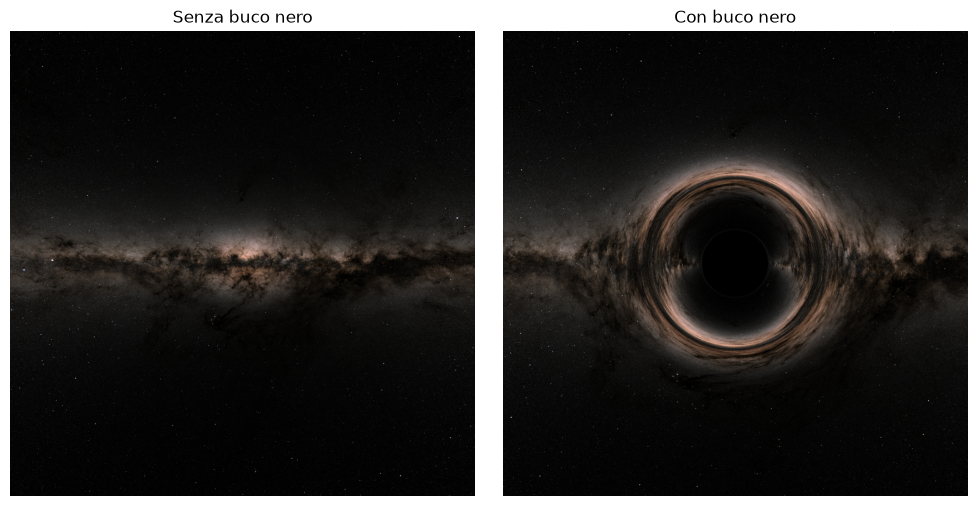

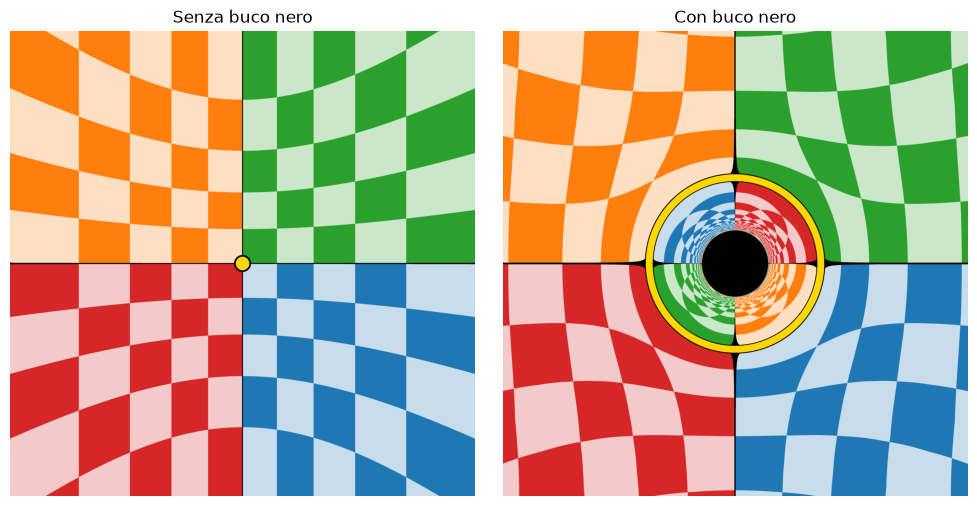

In [4]:
imgvuoto_sch1,imgbuco_sch1=immagine(f1,phi_pixel_sch ,black_sch,FOV,N)
Image.MAX_IMAGE_PIXELS = None   # il 16k supera la soglia di PIL
Image.fromarray((imgbuco_sch1[::-1] * 255 + 0.5).astype(np.uint8)).save(f"schw_{f1}_N={N}_r0={r0}_FOV={FOV*360/(2*np.pi)}°.png")
Image.fromarray((imgvuoto_sch1[::-1] * 255 + 0.5).astype(np.uint8)).save(f"vuoto_schw_{f1}_N={N}_r0={r0}_FOV={FOV*360/(2*np.pi)}°.png")
imgvuoto_sch2,imgbuco_sch2=immagine(f2,phi_pixel_sch ,black_sch,FOV,N)
Image.fromarray((imgbuco_sch2[::-1] * 255 + 0.5).astype(np.uint8)).save(f"schw_{f2}_N={N}_r0={r0}_FOV={FOV*360/(2*np.pi)}°.png")
Image.fromarray((imgvuoto_sch2[::-1] * 255 + 0.5).astype(np.uint8)).save(f"vuoto_schw_{f2}_N={N}_r0={r0}_FOV={FOV*360/(2*np.pi)}°.png")

# Kerr

In [ ]:
#       VARIABILI       #
M=1                     # Massa 
a=0.99                  # Spin
r0=30*M                 # distanza dal buco nero
th0=np.pi/2             # angolo iniziale
FOV=70*2*np.pi/360      # field of view
N=1000                  # numero di pixel per lato dell'immagine (N=1000 -> 152 minuti)
#########################
import subprocess, os

caff = subprocess.Popen(["caffeinate", "-i", "-w", str(os.getpid())])
try:
    phi_pixel_kerr,th_pixel,black_kerr=kerr(M,a,r0,th0,FOV,N)
    pass
finally:
    caff.terminate()
np.savez("kerr_data.npz", phi_pixel_kerr=phi_pixel_kerr, th_pixel=th_pixel, black_kerr=black_kerr)


In [ ]:
data = np.load("kerr_data.npz")
phi_pixel_kerr = data["phi_pixel_kerr"]
th_pixel = data["th_pixel"]
black_kerr = data["black_kerr"]

imgvuoto_kerr1,imgbuco_kerr1=immagine(f1,phi_pixel_kerr ,black_kerr,FOV,N,th_pixel)
Image.MAX_IMAGE_PIXELS = None   # il 16k supera la soglia di PIL
Image.fromarray((imgbuco_kerr1[::-1] * 255 + 0.5).astype(np.uint8)).save(f"kerr_{f1}_N={N}_r0={r0}_FOV={FOV*360/(2*np.pi)}°.png")
imgvuoto_kerr2,imgbuco_kerr2=immagine(f2,phi_pixel_kerr ,black_kerr,FOV,N,th_pixel)
Image.fromarray((imgbuco_kerr2[::-1] * 255 + 0.5).astype(np.uint8)).save(f"kerr_{f2}_N={N}_r0={r0}_FOV={FOV*360/(2*np.pi)}°.png")